#LangGraph - Overview

## Setup

In [1]:
!pip install langgraph langchain_core langchain_groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [langchain_groq]


In [2]:
!pip install grandalf

In [ ]:
# Set Groq API token
# In Prod should be done through .env files
import os
os.environ['GROQ_API_KEY'] = "<REPLACE WITH ACTUAL API KEY HERE>"

##Three parts to every graph in LangGraph
1. State *(the shared notebook every step reads from and writes to)*
2. Nodes *(the steps: plain Python functions that do the work)*
3. Edges *(the arrows: which step runs after which)*


03-assembly-line.svg

## Example 1 - Simple Mechanics of LangGraph

04-first-graph-walkthrough.svg

In [4]:
# Import TypeDict
from typing import TypedDict

# Define State
class State(TypedDict):
  text: str
  steps: int


In [5]:
# Build our Nodes

# shout function - node
def shout(state: State) -> dict:
  _text = str(state['text']).upper()
  _steps = state['steps'] + 1

  return {"text": _text, "steps": _steps}


# excite function - node
def excite(state: State) -> dict:
   _text = str(state['text']) + " !!!"
   _steps = state['steps'] + 1

   return {"text": _text, "steps": _steps}



In [6]:
# Wire the nodes
from langgraph.graph import StateGraph, START, END

# Build the Graph
builder = StateGraph(State)


# Add the nodes to the Graph
builder.add_node("shout", shout)
builder.add_node("excite", excite)


# Add the Edges
builder.add_edge(START, "shout")
builder.add_edge("shout", "excite")
builder.add_edge("excite", END)


# Compile the Graph
graph = builder.compile()


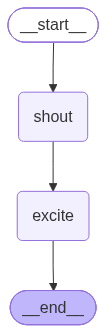

In [7]:
# Show the graph
graph

In [8]:
# Run the Workflow using INVOKE
initial_state = {"text" : "My Name is Subham", "steps": 0}

out = graph.invoke(initial_state)
print(out)

{'text': 'MY NAME IS SUBHAM !!!', 'steps': 2}


In [9]:
# Run using Stream - to check each values in state
for value in graph.stream(initial_state, stream_mode="values"):
  print(value)


{'text': 'My Name is Subham', 'steps': 0}
{'text': 'MY NAME IS SUBHAM', 'steps': 1}
{'text': 'MY NAME IS SUBHAM !!!', 'steps': 2}


In [10]:
# Run using Stream - to check each update at each node
for update in graph.stream(initial_state, stream_mode = "updates"):
  print(update)


{'shout': {'text': 'MY NAME IS SUBHAM', 'steps': 1}}
{'excite': {'text': 'MY NAME IS SUBHAM !!!', 'steps': 2}}
